# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.Fm Linear Regression Notebook
*By Mark Lambert - C00192497*

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 3rd November 2026*

*Start Date: 17th October 2026*

---

This notebook explores two regression questions using Last.fm scrobbles merged with Spotify track features:

- Does the average release year of music I scrobble change from week to week?

```%pip install pandas scikit-learn matplotlib```

### Load and prepare the scrobble data

Load the merged Last.fm and Spotify dataset, parses the scrobble date, and derives the calendar year and release decade.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

scrobbles = pd.read_csv('datasets/scrobbled_merged_with_hugging_face.csv')

# get year scrobbled 
scrobbles['date'] = pd.to_datetime(scrobbles['date'])
scrobbles['scrobble_year'] = scrobbles['date'].dt.year

# calculate release decade
scrobbles['release_decade'] = (scrobbles['release_year'] // 10) * 10

### Fit a linear trend to weekly averages

This cell groups scrobbles by week and calculates the average release year of tracks played each week. It uses week as the predictor and average release year as the response, then fits a straight line.

The slope describes weekly change, R-squared describes how much of the variation the line accounts for. The plot shows the observed averages and fitted trend.


Slope (Years changed per week): 0.037
R-squared: 0.1920
Total weeks analyzed: 39


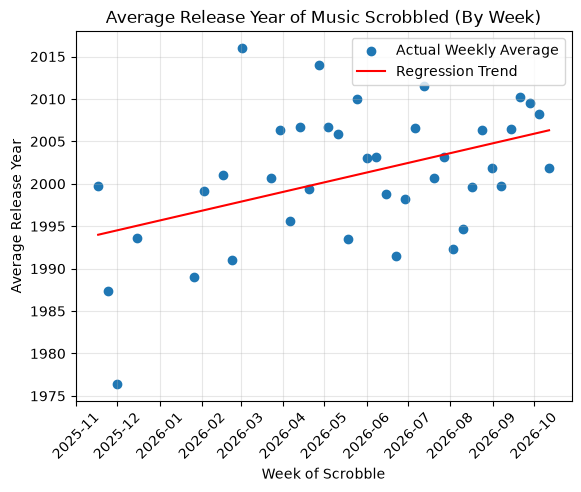

In [5]:
scrobbles = scrobbles.sort_values('date')
scrobbles['date'] = pd.to_datetime(scrobbles['date'])

# create a week col starts on Mondays
scrobbles['week'] = scrobbles['date'].dt.to_period('W').dt.start_time

# calculate the average release year
weekly_trend = scrobbles.groupby('week').agg(
    avg_release_year=('release_year', 'mean')
).reset_index()

# convert dates to ints for sklearn
weekly_trend['week_ordinal'] = weekly_trend['week'].apply(lambda x: x.toordinal())

X = weekly_trend[['week_ordinal']]
y = weekly_trend['avg_release_year']

# Adapted from PythonDataScienceHandbook/notebooks/05.06-Linear-Regression.ipynb:
# fit the estimator, then use predict() and score() for model evaluation
model = LinearRegression()
model.fit(X, y)

print(f"Slope (Years changed per week): {model.coef_[0]:.3f}")
print(f"R-squared: {model.score(X, y):.4f}")
print(f"Total weeks analyzed: {len(weekly_trend)}")

plt.scatter(weekly_trend['week'], y, label='Actual Weekly Average')

plt.plot(weekly_trend['week'], model.predict(X), color='red', label='Regression Trend')
plt.xticks(rotation=45)
plt.title('Average Release Year of Music Scrobbled (By Week)')
plt.xlabel('Week of Scrobble')
plt.ylabel('Average Release Year')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Express the trend as change per year

The earlier slope is measured per week.

This cell measures time in weeks since the first observation, refits the same model, and multiplies the slope by 52


In [ ]:
weekly_trend = weekly_trend.sort_values("week").reset_index(drop=True)
weekly_trend["weeks_since_start"] = (
    (weekly_trend["week"] - weekly_trend["week"].min()).dt.days / 7
)

X = weekly_trend[["weeks_since_start"]]
y = weekly_trend["avg_release_year"]

# Adapted from PythonDataScienceHandbook/notebooks/05.06-Linear-Regression.ipynb:
# refit the estimator on the interpretable time feature and report its slope
model.fit(X, y)
print(f"Change per year: {model.coef_[0] * 52:.2f} release years")

### Add weekly scrobble counts

This cell rebuilds the weekly summary with both average release year and the number of scrobbles in each week. The count is used to show how much listening supports each weekly average in the next plot


In [ ]:
weekly_trend = scrobbles.groupby("week").agg(
    avg_release_year=("release_year", "mean"),
    scrobble_count=("release_year", "count")
).reset_index()

### Fit a quadratic trend with annual seasonality

This cell extends the straight-line model with a squared time term and sine/cosine features for the week of the year

The quadratic term represents a curved long-term trend, the seasonal terms represent an annual cycle

Note that the model is evaluated on the same 39 weeks used to fit it, not on held-out weeks

The polynomial basis approach is adapted from PythonDataScienceHandbook/notebooks/05.06-Linear-Regression.ipynb


In [ ]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures

weekly_trend = weekly_trend.sort_values("week").reset_index(drop=True)

# Time in years since the first week, for an interpretable trend scale
weekly_trend["time_years"] = (
    (weekly_trend["week"] - weekly_trend["week"].min()).dt.days / 365.25
)

# Annual seasonal features based on each week's position in the year
week_of_year = weekly_trend["week"].dt.isocalendar().week.astype(float)
weekly_trend["season_sin"] = np.sin(2 * np.pi * week_of_year / 52.18)
weekly_trend["season_cos"] = np.cos(2 * np.pi * week_of_year / 52.18)

# Adapted from PythonDataScienceHandbook/notebooks/05.06-Linear-Regression.ipynb:
poly = PolynomialFeatures(degree=2, include_bias=False)
time_features = poly.fit_transform(weekly_trend[["time_years"]])

X = np.column_stack([
    time_features,
    weekly_trend[["season_sin", "season_cos"]].to_numpy()
])
y = weekly_trend["avg_release_year"]

model = LinearRegression()
model.fit(X, y)

weekly_trend["predicted"] = model.predict(X)

print(f"R-squared: {model.score(X, y):.4f}")
print(f"Weeks analyzed: {len(weekly_trend)}")

plt.scatter(
    weekly_trend["week"],
    y,
    s=weekly_trend["scrobble_count"] if "scrobble_count" in weekly_trend else 20,
    alpha=0.5,
    label="Weekly average"
)
plt.plot(
    weekly_trend["week"],
    weekly_trend["predicted"],
    color="red",
    label="Quadratic trend + annual seasonality"
)
plt.title("Average Release Year of Scrobbled Music")
plt.xlabel("Week")
plt.ylabel("Average release year")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Conclusion

The quadratic trend with annual seasonality has an in-sample R-squared of **0.3574**, compared with **0.1920** for the straight-line model. This means the added curve and seasonal features fit the observed weekly averages better across these 39 weeks. The estimated long-term direction is upward, at about 13.62 release years per year in this sample.

This is an exploratory result, not evidence that the model will predict future weeks accurately: it was evaluated on the same weeks used to fit it, and the observation period is short. More weeks would be needed to check whether the trend continues